# RQ4 — Do redundancy control and homology separation interact?

## Scientific question

**Do redundancy reduction (`R`) and train–test homology separation (`S`) act independently, or does changing one factor alter the effect of the other?**

The full supervised benchmark contains the complete:

\[
4\times4 \; R\times S
\]

surface for every `task × representation × algorithm`.

RQ2 showed that redundancy reduction has a substantial but heterogeneous effect.  
RQ3 showed that the effect of homology separation progressively collapses as `R` becomes stricter.

RQ4 formalizes that observation.

### Interaction definition

For any rectangle:

\[
R_{\mathrm{loose}} > R_{\mathrm{strict}}
\]

and

\[
S_{\mathrm{loose}} > S_{\mathrm{strict}},
\]

define:

\[
I =
\left[
M(R_s,S_s)-M(R_l,S_s)
\right]
-
\left[
M(R_s,S_l)-M(R_l,S_l)
\right].
\]

Equivalently:

\[
I =
\Delta S\mid R_s
-
\Delta S\mid R_l.
\]

Thus:

- `I > 0`: the strict-strict corner performs **better than an additive model predicts**; the penalties attenuate/substitute one another when the main effects are negative.
- `I ≈ 0`: approximately additive behavior.
- `I < 0`: the strict-strict corner performs **worse than additive expectation**; the constraints amplify one another when the main effects are negative.

This notebook analyzes **all 36 possible 2×2 rectangles** in each 4×4 surface, not only the extreme corners.

## Interpretation contract

- Interaction is calculated over **native-test factorial cells**. It is not an entity-level paired interaction.
- Positive/negative interaction has a precise mathematical meaning. Terms such as *attenuation*, *substitution*, *amplification*, or *synergy* are used only when the corresponding main effects are predominantly detrimental.
- The primary interaction metric is MCC.
- Binary threshold-free sensitivity is checked using ROC-AUC and prevalence-normalized AP skill.
- Multiclass behavior is additionally checked with macro-F1 when available.
- No mass null-hypothesis testing is performed here. Interaction magnitude, direction, consistency, and geometry are the primary evidence.
- Common-test validation and bootstrap uncertainty are reserved for their dedicated analyses.

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

R_PAIRS = list(combinations(R_LEVELS, 2))
S_PAIRS = list(combinations(S_LEVELS, 2))

ADJ_R_PAIRS = [(90, 70), (70, 50), (50, 30)]
ADJ_S_PAIRS = [(90, 70), (70, 50), (50, 30)]

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12A and Stage12B."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

interactions = pd.read_csv(
    STAGE12B / "rs_all_interaction_rectangles.tsv",
    sep="\t",
    low_memory=False,
)

r_deltas = pd.read_csv(
    STAGE12B / "rs_redundancy_deltas_fixed_S.tsv",
    sep="\t",
    low_memory=False,
)

s_deltas = pd.read_csv(
    STAGE12B / "rs_split_deltas_fixed_R.tsv",
    sep="\t",
    low_memory=False,
)

print("Experiment families:", len(master))
print("Interaction rows:", len(interactions))
print("Interaction metrics:", sorted(interactions["metric"].dropna().unique()))
print("Tasks:", sorted(master["task"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_cells")
    .reset_index()
)

assert coverage["n_cells"].eq(16).all(), "Incomplete R×S surface detected."

mcc_interactions = interactions[interactions["metric"].eq("mcc")].copy()

expected_mcc_interactions = (
    master[["task", "representation", "algorithm"]]
    .drop_duplicates()
    .shape[0]
    * 36
)

print("MCC interaction rows:", len(mcc_interactions))
print("Expected MCC rows:", expected_mcc_interactions)

assert len(mcc_interactions) == expected_mcc_interactions

Experiment families: 2240
Interaction rows: 14400
Interaction metrics: ['ap', 'ap_gain', 'macro_f1', 'mcc']
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
MCC interaction rows: 5040
Expected MCC rows: 5040


## 1. Verify interaction equivalence

In [3]:
eq_error = (
    mcc_interactions["interaction"]
    - mcc_interactions["interaction_equivalence_check"]
).abs()

print("Max equivalence error:", eq_error.max())
assert eq_error.max() < 1e-10, "Interaction equivalence check failed."

Max equivalence error: 1.1102230246251565e-16


The equality:

\[
\Delta R\mid S_{\mathrm{strict}}
-
\Delta R\mid S_{\mathrm{loose}}
=
\Delta S\mid R_{\mathrm{strict}}
-
\Delta S\mid R_{\mathrm{loose}}
\]

must hold numerically for every rectangle.

## 2. Global interaction distribution across all 36 rectangles

In [4]:
def summarize_interaction(x):
    x = pd.Series(x).dropna()
    return pd.Series(
        {
            "n": len(x),
            "mean": x.mean(),
            "median": x.median(),
            "std": x.std(),
            "q10": x.quantile(0.10),
            "q25": x.quantile(0.25),
            "q75": x.quantile(0.75),
            "q90": x.quantile(0.90),
            "min": x.min(),
            "max": x.max(),
            "fraction_positive": (x > 0).mean(),
            "fraction_negative": (x < 0).mean(),
            "median_abs": x.abs().median(),
            "mean_abs": x.abs().mean(),
        }
    )

global_interaction_summary = summarize_interaction(
    mcc_interactions["interaction"]
).to_frame("MCC interaction")

display(global_interaction_summary)

,MCC interaction
n,5040.000000
mean,0.031515
median,0.014679
std,0.089226
q10,-0.032437
q25,-0.007681
q75,0.050353
q90,0.104398
min,-0.625523
max,0.949204


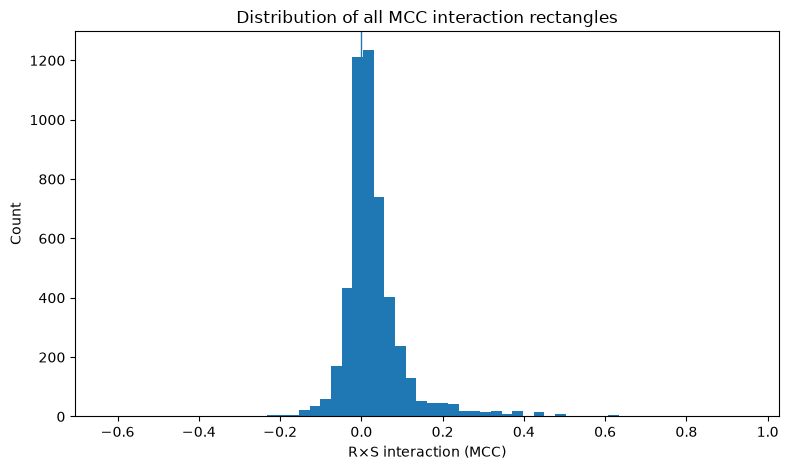

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(
    mcc_interactions["interaction"].dropna(),
    bins=60,
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("R×S interaction (MCC)")
ax.set_ylabel("Count")
ax.set_title("Distribution of all MCC interaction rectangles")
plt.tight_layout()
plt.show()

## 3. Sensitivity to the definition of “approximately additive”

A single tolerance is arbitrary. We therefore inspect several transparent MCC tolerances.

For a tolerance `τ`:

- `interaction > τ`: positive / attenuating relative to additivity;
- `|interaction| ≤ τ`: approximately additive;
- `interaction < -τ`: negative / amplifying relative to additivity.

In [6]:
tolerance_rows = []

for tol in [0.005, 0.010, 0.020, 0.050]:
    x = mcc_interactions["interaction"]

    tolerance_rows.append(
        {
            "tolerance": tol,
            "positive_fraction": (x > tol).mean(),
            "near_additive_fraction": (x.abs() <= tol).mean(),
            "negative_fraction": (x < -tol).mean(),
        }
    )

tolerance_summary = pd.DataFrame(tolerance_rows)
display(tolerance_summary)

INTERACTION_TOL = 0.010

def classify_interaction(value, tol=INTERACTION_TOL):
    if pd.isna(value):
        return np.nan
    if value > tol:
        return "positive_nonadditive"
    if value < -tol:
        return "negative_nonadditive"
    return "approximately_additive"

mcc_interactions["interaction_class"] = (
    mcc_interactions["interaction"]
    .map(classify_interaction)
)

display(
    mcc_interactions["interaction_class"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

,tolerance,positive_fraction,near_additive_fraction,negative_fraction
0,0.005,0.604563,0.118849,0.276587
1,0.010,0.550000,0.220437,0.229563
2,0.020,0.453968,0.387103,0.158929
3,0.050,0.251587,0.688294,0.060119


,fraction
interaction_class,
positive_nonadditive,0.550000
negative_nonadditive,0.229563
approximately_additive,0.220437


## 4. Extreme R90/R30 × S90/S30 interaction

In [7]:
extreme = mcc_interactions[
    mcc_interactions["R_loose"].eq(90)
    & mcc_interactions["R_strict"].eq(30)
    & mcc_interactions["S_loose"].eq(90)
    & mcc_interactions["S_strict"].eq(30)
].copy()

expected_extreme = (
    master[["task", "representation", "algorithm"]]
    .drop_duplicates()
    .shape[0]
)

print("Extreme rows:", len(extreme), "/", expected_extreme)
assert len(extreme) == expected_extreme

display(
    summarize_interaction(
        extreme["interaction"]
    ).to_frame("extreme interaction")
)

Extreme rows: 140 / 140


,extreme interaction
n,140.000000
mean,0.096134
median,0.051116
std,0.135443
q10,-0.003893
q25,0.014241
q75,0.114524
q90,0.301702
min,-0.043694
max,0.661494


### Additive strict-corner expectation

Starting at `R90_S90`, an additive model predicts:

\[
M_{\mathrm{add}}(R30,S30)
=
M_{90,90}
+
\Delta R_{90\to30}\mid S90
+
\Delta S_{90\to30}\mid R90.
\]

Because of the interaction definition:

\[
M_{\mathrm{observed}}(R30,S30)
-
M_{\mathrm{add}}(R30,S30)
=
I.
\]

In [8]:
extreme["additive_prediction_R30_S30"] = (
    extreme["M_Rloose_Sloose"]
    + extreme["delta_R_at_Sloose"]
    + extreme["delta_S_at_Rloose"]
)

extreme["observed_joint_delta"] = (
    extreme["M_Rstrict_Sstrict"]
    - extreme["M_Rloose_Sloose"]
)

extreme["additive_joint_delta"] = (
    extreme["delta_R_at_Sloose"]
    + extreme["delta_S_at_Rloose"]
)

extreme["strict_corner_residual"] = (
    extreme["M_Rstrict_Sstrict"]
    - extreme["additive_prediction_R30_S30"]
)

assert np.allclose(
    extreme["strict_corner_residual"],
    extreme["interaction"],
)

display(
    extreme[
        [
            "task",
            "representation",
            "algorithm",
            "M_Rloose_Sloose",
            "delta_R_at_Sloose",
            "delta_S_at_Rloose",
            "additive_prediction_R30_S30",
            "M_Rstrict_Sstrict",
            "interaction",
        ]
    ].head()
)

,task,representation,algorithm,M_Rloose_Sloose,delta_R_at_Sloose,delta_S_at_Rloose,additive_prediction_R30_S30,M_Rstrict_Sstrict,interaction
14,global_easy,esm2_t30_150m,KNN,0.962580,-0.078885,-0.014544,0.869152,0.887662,0.018510
50,global_easy,esm2_t30_150m,LR,0.929346,-0.102370,-0.011355,0.815622,0.840543,0.024921
86,global_easy,esm2_t30_150m,MLP,0.960914,-0.079483,-0.019913,0.861518,0.877293,0.015774
122,global_easy,esm2_t30_150m,RF,0.931977,-0.118027,-0.017760,0.796189,0.831723,0.035534
158,global_easy,esm2_t30_150m,XGB,0.956669,-0.085121,-0.019789,0.851760,0.879389,0.027629


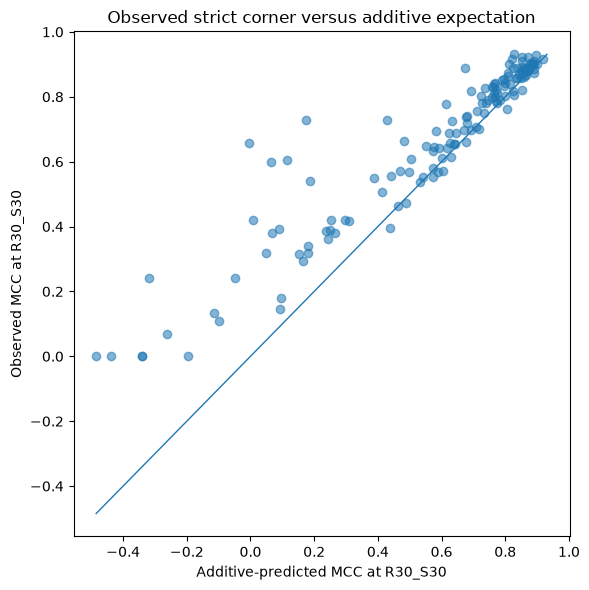

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    extreme["additive_prediction_R30_S30"],
    extreme["M_Rstrict_Sstrict"],
    alpha=0.55,
)

lo = min(
    extreme["additive_prediction_R30_S30"].min(),
    extreme["M_Rstrict_Sstrict"].min(),
)
hi = max(
    extreme["additive_prediction_R30_S30"].max(),
    extreme["M_Rstrict_Sstrict"].max(),
)

ax.plot([lo, hi], [lo, hi], linewidth=1)
ax.set_xlabel("Additive-predicted MCC at R30_S30")
ax.set_ylabel("Observed MCC at R30_S30")
ax.set_title("Observed strict corner versus additive expectation")
plt.tight_layout()
plt.show()

## 5. How much of the additive penalty is offset by interaction?

In [10]:
# Only interpret this ratio when the additive expectation is a meaningful penalty.
MIN_ADDITIVE_PENALTY = 0.05

extreme["interaction_offset_fraction"] = np.where(
    extreme["additive_joint_delta"] <= -MIN_ADDITIVE_PENALTY,
    extreme["interaction"]
    / extreme["additive_joint_delta"].abs(),
    np.nan,
)

valid_offset = extreme["interaction_offset_fraction"].dropna()

display(
    valid_offset.agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).to_frame("interaction_offset_fraction")
)

print(
    "Fraction of eligible surfaces where interaction offsets >25% "
    "of additive penalty:",
    (valid_offset > 0.25).mean(),
)

print(
    "Fraction where interaction offsets >50%:",
    (valid_offset > 0.50).mean(),
)

,interaction_offset_fraction
count,117.000000
mean,0.368301
median,0.327737
std,0.298712
min,-0.622795
max,1.103100


Fraction of eligible surfaces where interaction offsets >25% of additive penalty: 0.7264957264957265
Fraction where interaction offsets >50%: 0.23931623931623933


A value of `0.5` means that the positive interaction recovers half of the performance loss predicted by adding the isolated R and S penalties measured at the permissive corner.

Values can exceed `1` if the strict-strict performance is better than the permissive-corner additive model would imply by more than the entire expected penalty.

## 6. Extreme interaction by biological task

In [11]:
task_extreme = (
    extreme.groupby("task")["interaction"]
    .apply(summarize_interaction)
    .unstack()
    .sort_values("median", ascending=False)
)

display(task_extreme)

,n,mean,median,std,q10,q25,q75,q90,min,max,fraction_positive,fraction_negative,median_abs,mean_abs
task,,,,,,,,,,,,,,
subtype_val,20.0,0.354234,0.339206,0.164895,0.154724,0.271421,0.485644,0.557182,0.054128,0.661494,1.00,0.00,0.339206,0.354234
subtype_endolysin,20.0,0.094910,0.080343,0.088916,0.010025,0.034945,0.130946,0.174602,-0.040897,0.329699,0.95,0.05,0.080343,0.098999
subtype_depolymerase,20.0,0.058496,0.061084,0.050058,-0.000314,0.019449,0.090737,0.104701,-0.015904,0.180169,0.90,0.10,0.061084,0.061381
global_easy,20.0,0.068535,0.047088,0.066089,0.014621,0.026952,0.085168,0.159773,-0.014544,0.249226,0.95,0.05,0.047088,0.069989
multiclass_clean,20.0,0.031212,0.028747,0.031202,-0.000464,0.013806,0.055165,0.064242,-0.032466,0.097878,0.90,0.10,0.029222,0.036446
global_hard,20.0,0.026313,0.021067,0.033592,-0.006225,0.006092,0.041766,0.064318,-0.032326,0.112449,0.80,0.20,0.022814,0.032169
global_mixed,20.0,0.039235,0.010090,0.068870,-0.019093,-0.002104,0.105411,0.123871,-0.043694,0.210352,0.70,0.30,0.017270,0.049865


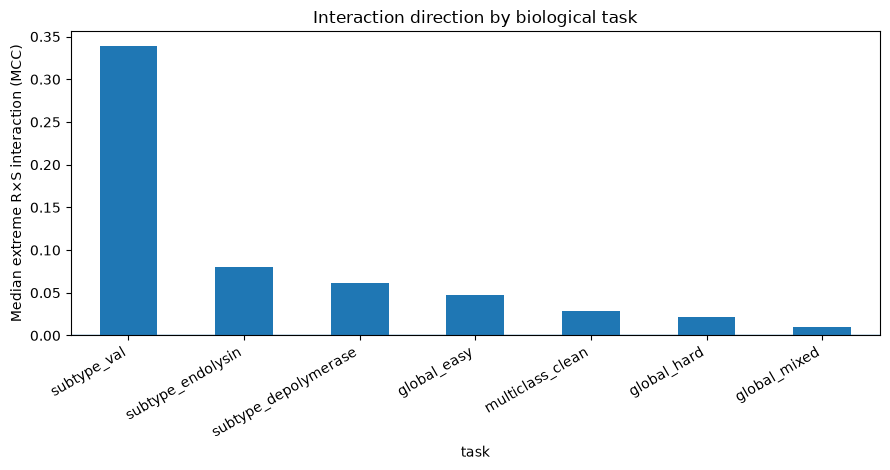

In [12]:
task_extreme["median"].plot(
    kind="bar",
    figsize=(9, 4.8),
)
plt.axhline(0, linewidth=1)
plt.ylabel("Median extreme R×S interaction (MCC)")
plt.title("Interaction direction by biological task")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 7. Extreme interaction by representation

In [13]:
rep_extreme = (
    extreme.groupby("representation")["interaction"]
    .apply(summarize_interaction)
    .unstack()
    .sort_values("median", ascending=False)
)

display(rep_extreme)

,n,mean,median,std,q10,q25,q75,q90,min,max,fraction_positive,fraction_negative,median_abs,mean_abs
representation,,,,,,,,,,,,,,
onehot_1024,35.0,0.140924,0.121947,0.129409,-0.007897,0.039849,0.187993,0.335403,-0.032466,0.484608,0.885714,0.114286,0.121947,0.145815
roxy_48,35.0,0.083053,0.057686,0.119737,-0.013902,0.013692,0.095289,0.239496,-0.040897,0.561891,0.857143,0.142857,0.057686,0.089877
esm2_t6_8m,35.0,0.106989,0.045886,0.180767,0.003887,0.013195,0.069696,0.457946,-0.043694,0.661494,0.942857,0.057143,0.045886,0.109570
esm2_t30_150m,35.0,0.053568,0.026744,0.083728,-0.003953,0.009700,0.053992,0.139084,-0.022596,0.355574,0.857143,0.142857,0.026744,0.056499


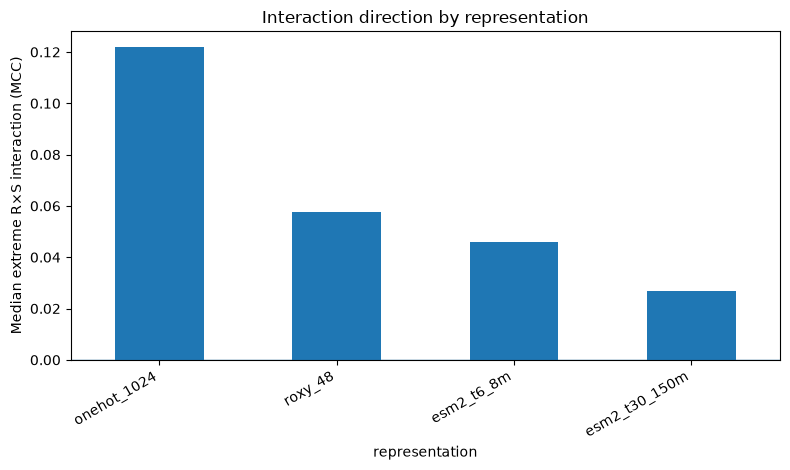

In [14]:
rep_extreme["median"].plot(
    kind="bar",
    figsize=(8, 4.8),
)
plt.axhline(0, linewidth=1)
plt.ylabel("Median extreme R×S interaction (MCC)")
plt.title("Interaction direction by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 8. Extreme interaction by learner

In [15]:
alg_extreme = (
    extreme.groupby("algorithm")["interaction"]
    .apply(summarize_interaction)
    .unstack()
    .sort_values("median", ascending=False)
)

display(alg_extreme)

,n,mean,median,std,q10,q25,q75,q90,min,max,fraction_positive,fraction_negative,median_abs,mean_abs
algorithm,,,,,,,,,,,,,,
KNN,28.0,0.132226,0.080773,0.169087,0.017391,0.024994,0.160070,0.334744,-0.015835,0.661494,0.964286,0.035714,0.080773,0.133357
MLP,28.0,0.089060,0.062844,0.125447,0.005532,0.011936,0.105411,0.209033,-0.043694,0.556659,0.928571,0.071429,0.062844,0.093317
XGB,28.0,0.102132,0.054489,0.135291,0.006303,0.023100,0.110018,0.304298,-0.019872,0.534720,0.964286,0.035714,0.054489,0.103552
RF,28.0,0.093303,0.044306,0.126255,-0.017761,0.008498,0.117165,0.301895,-0.032466,0.411736,0.785714,0.214286,0.044306,0.100195
LR,28.0,0.063946,0.026851,0.115534,-0.013421,0.000894,0.070869,0.162095,-0.040897,0.488752,0.785714,0.214286,0.030807,0.071781


## 9. Local interaction geometry: all 3×3 adjacent rectangles

The extreme rectangle can hide where the interaction actually arises.

Adjacent R intervals:

- `R90→R70`
- `R70→R50`
- `R50→R30`

Adjacent S intervals:

- `S90→S70`
- `S70→S50`
- `S50→S30`

produce a `3×3` map of **local interaction**.

In [16]:
local = mcc_interactions[
    mcc_interactions.apply(
        lambda x: (
            (int(x["R_loose"]), int(x["R_strict"])) in ADJ_R_PAIRS
            and
            (int(x["S_loose"]), int(x["S_strict"])) in ADJ_S_PAIRS
        ),
        axis=1,
    )
].copy()

local["R_step"] = (
    "R"
    + local["R_loose"].astype(str)
    + "→R"
    + local["R_strict"].astype(str)
)

local["S_step"] = (
    "S"
    + local["S_loose"].astype(str)
    + "→S"
    + local["S_strict"].astype(str)
)

expected_local = expected_extreme * 9
print("Local rectangles:", len(local), "/", expected_local)
assert len(local) == expected_local

local_matrix = (
    local.groupby(["R_step", "S_step"])["interaction"]
    .median()
    .unstack()
    .reindex(
        index=["R90→R70", "R70→R50", "R50→R30"],
        columns=["S90→S70", "S70→S50", "S50→S30"],
    )
)

display(local_matrix)

Local rectangles: 1260 / 1260


S_step,S90→S70,S70→S50,S50→S30
R_step,,,
R90→R70,0.017653,-0.007738,0.002296
R70→R50,-0.010523,0.033653,0.007620
R50→R30,0.001915,-0.001654,0.007364


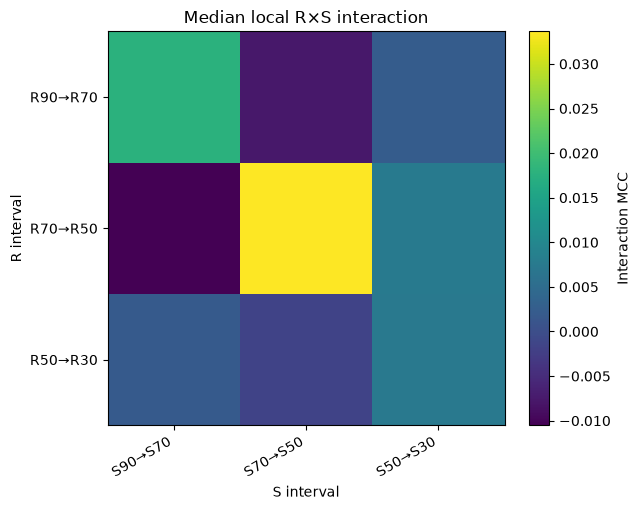

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(local_matrix.to_numpy(), aspect="auto")

ax.set_xticks(
    range(len(local_matrix.columns)),
    local_matrix.columns,
    rotation=30,
    ha="right",
)
ax.set_yticks(
    range(len(local_matrix.index)),
    local_matrix.index,
)

ax.set_xlabel("S interval")
ax.set_ylabel("R interval")
ax.set_title("Median local R×S interaction")
plt.colorbar(im, ax=ax, label="Interaction MCC")
plt.tight_layout()
plt.show()

## 10. Which local rectangle carries the strongest interaction?

In [18]:
dominant_local = (
    local.assign(abs_interaction=local["interaction"].abs())
    .sort_values(
        [
            "task",
            "representation",
            "algorithm",
            "abs_interaction",
        ],
        ascending=[True, True, True, False],
        kind="stable",
    )
    .groupby(
        ["task", "representation", "algorithm"],
        as_index=False,
    )
    .first()
)

dominant_local["rectangle"] = (
    dominant_local["R_step"]
    + " × "
    + dominant_local["S_step"]
)

display(
    dominant_local["rectangle"]
    .value_counts(normalize=True)
    .rename("fraction_of_model_surfaces")
    .to_frame()
)

,fraction_of_model_surfaces
rectangle,
R70→R50 × S70→S50,0.200000
R90→R70 × S50→S30,0.178571
R90→R70 × S70→S50,0.150000
R50→R30 × S50→S30,0.135714
R90→R70 × S90→S70,0.121429
R70→R50 × S90→S70,0.071429
R70→R50 × S50→S30,0.064286
R50→R30 × S90→S70,0.050000
R50→R30 × S70→S50,0.028571


In [19]:
dominant_by_task = (
    dominant_local.groupby(["task", "rectangle"])
    .size()
    .rename("n")
    .reset_index()
)

dominant_by_task["fraction_within_task"] = (
    dominant_by_task["n"]
    / dominant_by_task.groupby("task")["n"].transform("sum")
)

display(
    dominant_by_task.sort_values(
        ["task", "fraction_within_task"],
        ascending=[True, False],
    )
)

,task,rectangle,n,fraction_within_task
4,global_easy,R70→R50 × S70→S50,5,0.25
3,global_easy,R70→R50 × S50→S30,3,0.15
5,global_easy,R90→R70 × S50→S30,3,0.15
6,global_easy,R90→R70 × S90→S70,3,0.15
0,global_easy,R50→R30 × S50→S30,2,0.10
1,global_easy,R50→R30 × S70→S50,2,0.10
2,global_easy,R50→R30 × S90→S70,2,0.10
13,global_hard,R90→R70 × S70→S50,6,0.30
12,global_hard,R90→R70 × S50→S30,4,0.20
10,global_hard,R70→R50 × S70→S50,3,0.15


## 11. Extreme interaction is exactly the change in S effect across R

In [20]:
conditioning = (
    extreme.groupby(["task", "representation", "algorithm"], as_index=False)
    .agg(
        S_effect_at_R90=("delta_S_at_Rloose", "first"),
        S_effect_at_R30=("delta_S_at_Rstrict", "first"),
        R_effect_at_S90=("delta_R_at_Sloose", "first"),
        R_effect_at_S30=("delta_R_at_Sstrict", "first"),
        interaction=("interaction", "first"),
    )
)

conditioning["S_effect_change_R30_minus_R90"] = (
    conditioning["S_effect_at_R30"]
    - conditioning["S_effect_at_R90"]
)

conditioning["R_effect_change_S30_minus_S90"] = (
    conditioning["R_effect_at_S30"]
    - conditioning["R_effect_at_S90"]
)

assert np.allclose(
    conditioning["S_effect_change_R30_minus_R90"],
    conditioning["interaction"],
)

assert np.allclose(
    conditioning["R_effect_change_S30_minus_S90"],
    conditioning["interaction"],
)

display(conditioning.head())

,task,representation,algorithm,S_effect_at_R90,S_effect_at_R30,R_effect_at_S90,R_effect_at_S30,interaction,S_effect_change_R30_minus_R90,R_effect_change_S30_minus_S90
0,global_easy,esm2_t30_150m,KNN,-0.014544,0.003966,-0.078885,-0.060375,0.018510,0.018510,0.018510
1,global_easy,esm2_t30_150m,LR,-0.011355,0.013566,-0.102370,-0.077449,0.024921,0.024921,0.024921
2,global_easy,esm2_t30_150m,MLP,-0.019913,-0.004139,-0.079483,-0.063709,0.015774,0.015774,0.015774
3,global_easy,esm2_t30_150m,RF,-0.017760,0.017774,-0.118027,-0.082493,0.035534,0.035534,0.035534
4,global_easy,esm2_t30_150m,XGB,-0.019789,0.007840,-0.085121,-0.057492,0.027629,0.027629,0.027629


## 12. Direct visualization of effect attenuation

In [21]:
s_conditioning_summary = pd.DataFrame(
    {
        "R": [90, 30],
        "median_S90_to_S30_effect": [
            extreme["delta_S_at_Rloose"].median(),
            extreme["delta_S_at_Rstrict"].median(),
        ],
        "mean_S90_to_S30_effect": [
            extreme["delta_S_at_Rloose"].mean(),
            extreme["delta_S_at_Rstrict"].mean(),
        ],
    }
)

r_conditioning_summary = pd.DataFrame(
    {
        "S": [90, 30],
        "median_R90_to_R30_effect": [
            extreme["delta_R_at_Sloose"].median(),
            extreme["delta_R_at_Sstrict"].median(),
        ],
        "mean_R90_to_R30_effect": [
            extreme["delta_R_at_Sloose"].mean(),
            extreme["delta_R_at_Sstrict"].mean(),
        ],
    }
)

print("S effect conditioned by R")
display(s_conditioning_summary)

print("R effect conditioned by S")
display(r_conditioning_summary)

S effect conditioned by R


,R,median_S90_to_S30_effect,mean_S90_to_S30_effect
0,90,-4.713108e-02,-0.095582
1,30,4.334396e-07,0.000551


R effect conditioned by S


,S,median_R90_to_R30_effect,mean_R90_to_R30_effect
0,90,-0.084248,-0.116321
1,30,-0.039645,-0.020187


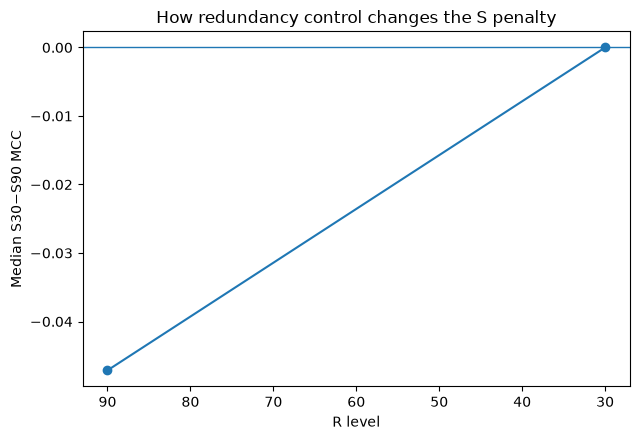

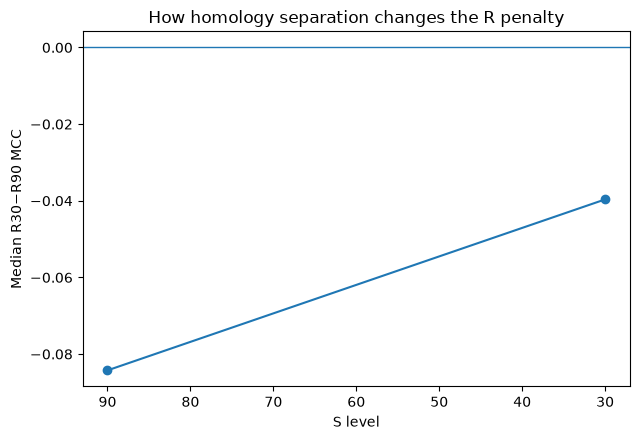

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(
    s_conditioning_summary["R"],
    s_conditioning_summary["median_S90_to_S30_effect"],
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("R level")
ax.set_ylabel("Median S30−S90 MCC")
ax.set_title("How redundancy control changes the S penalty")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(
    r_conditioning_summary["S"],
    r_conditioning_summary["median_R90_to_R30_effect"],
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("S level")
ax.set_ylabel("Median R30−R90 MCC")
ax.set_title("How homology separation changes the R penalty")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 13. Full conditioning curves, not only extreme levels

For every R, calculate the extreme S90→S30 effect.

For every S, calculate the extreme R90→R30 effect.

These are the complete marginal-effect trajectories underlying the extreme interaction.

In [23]:
mcc_r = r_deltas[r_deltas["metric"].eq("mcc")].copy()
mcc_s = s_deltas[s_deltas["metric"].eq("mcc")].copy()

r90_30_by_s = (
    mcc_r[
        mcc_r["R_from"].eq(90)
        & mcc_r["R_to"].eq(30)
    ]
    .groupby("S_fixed")["delta"]
    .agg(["mean", "median", "std", "min", "max"])
    .reindex(S_LEVELS)
)

s90_30_by_r = (
    mcc_s[
        mcc_s["S_from"].eq(90)
        & mcc_s["S_to"].eq(30)
    ]
    .groupby("R_fixed")["delta"]
    .agg(["mean", "median", "std", "min", "max"])
    .reindex(R_LEVELS)
)

print("R90→R30 effect at each S")
display(r90_30_by_s)

print("S90→S30 effect at each R")
display(s90_30_by_r)

R90→R30 effect at each S


,mean,median,std,min,max
S_fixed,,,,,
90,-0.116321,-0.084248,0.117180,-0.513991,0.096261
70,-0.089129,-0.091481,0.090254,-0.460824,0.182626
50,-0.067048,-0.069663,0.083282,-0.389728,0.149091
30,-0.020187,-0.039645,0.108345,-0.243474,0.514487


S90→S30 effect at each R


,mean,median,std,min,max
R_fixed,,,,,
90,-0.095582,-4.713108e-02,0.134601,-0.693917,0.067330
70,-0.055813,-3.105599e-02,0.088347,-0.492527,0.029314
50,-0.003931,-5.682645e-03,0.046466,-0.158304,0.254274
30,0.000551,4.334396e-07,0.028706,-0.101726,0.131319


## 14. Descriptive factorial variance decomposition

A complementary way to quantify non-additivity is to decompose each 4×4 MCC surface into:

\[
M_{ij}
=
\mu
+
R_i
+
S_j
+
(RS)_{ij}.
\]

For each `task × representation × algorithm`, calculate:

- `SS_R`: variation associated with row means;
- `SS_S`: variation associated with column means;
- `SS_interaction`: residual departure from an additive surface;
- their fractions of total 4×4 surface variation.

This is a **geometric/descriptive decomposition**, not an inferential ANOVA: there are no replicate observations per factorial cell.

In [24]:
decomposition_rows = []
residual_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    surface = (
        grp.pivot_table(
            index="R",
            columns="S",
            values="mcc",
            aggfunc="first",
        )
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

    if surface.isna().any().any():
        continue

    matrix = surface.to_numpy(dtype=float)
    grand = matrix.mean()

    row_means = matrix.mean(axis=1)
    col_means = matrix.mean(axis=0)

    r_effect = row_means - grand
    s_effect = col_means - grand

    additive = (
        grand
        + r_effect[:, None]
        + s_effect[None, :]
    )

    residual = matrix - additive

    ss_r = len(S_LEVELS) * np.sum(r_effect ** 2)
    ss_s = len(R_LEVELS) * np.sum(s_effect ** 2)
    ss_int = np.sum(residual ** 2)
    ss_total = np.sum((matrix - grand) ** 2)

    decomposition_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "ss_total": ss_total,
            "ss_R": ss_r,
            "ss_S": ss_s,
            "ss_interaction": ss_int,
            "fraction_R": ss_r / ss_total if ss_total > 0 else np.nan,
            "fraction_S": ss_s / ss_total if ss_total > 0 else np.nan,
            "fraction_interaction": (
                ss_int / ss_total
                if ss_total > 0
                else np.nan
            ),
            "interaction_rms": float(np.sqrt(np.mean(residual ** 2))),
            "interaction_max_abs_residual": float(np.max(np.abs(residual))),
        }
    )

    for i, r in enumerate(R_LEVELS):
        for j, s in enumerate(S_LEVELS):
            residual_rows.append(
                {
                    "task": task,
                    "representation": rep,
                    "algorithm": alg,
                    "R": r,
                    "S": s,
                    "observed_mcc": matrix[i, j],
                    "additive_mcc": additive[i, j],
                    "additive_residual": residual[i, j],
                }
            )

decomposition = pd.DataFrame(decomposition_rows)
additive_residuals = pd.DataFrame(residual_rows)

print("Factorial surfaces decomposed:", len(decomposition))
display(
    decomposition[
        [
            "fraction_R",
            "fraction_S",
            "fraction_interaction",
            "interaction_rms",
        ]
    ].describe()
)

Factorial surfaces decomposed: 140


,fraction_R,fraction_S,fraction_interaction,interaction_rms
count,140.000000,140.000000,140.000000,140.000000
mean,0.608916,0.124405,0.266679,0.024798
std,0.290394,0.113455,0.223039,0.025469
min,0.016155,0.002045,0.013245,0.002494
25%,0.316220,0.036377,0.068462,0.010655
50%,0.705293,0.091297,0.183435,0.016714
75%,0.872300,0.194841,0.408318,0.025375
max,0.983547,0.616557,0.823608,0.148598


## 15. Interaction fraction by task and representation

In [25]:
display(
    decomposition.groupby("task")[
        ["fraction_R", "fraction_S", "fraction_interaction", "interaction_rms"]
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

display(
    decomposition.groupby("representation")[
        ["fraction_R", "fraction_S", "fraction_interaction", "interaction_rms"]
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

fraction_R                                         fraction_S                                         fraction_interaction                                         interaction_rms            \
                           mean    median       std       min       max       mean    median       std       min       max                 mean    median       std       min       max            mean    median   
task                                                                                                                                                                                                                
global_easy            0.818248  0.827489  0.127074  0.485064  0.983547   0.069904  0.051517  0.066129  0.003208  0.278121             0.111849  0.086404  0.081626  0.013245  0.343762        0.016067  0.012647   
global_hard            0.714952  0.772704  0.168566  0.413262  0.927896   0.095193  0.073905  0.086223  0.002045  0.283753             0.189855  0.179892  0.098335  0.035086  0.383854        0.010845  0.009205   
global_mixed           0.825032  0.836565  0.104034  0.528990  0.957489   0.089554  0.085993  0.055648  0.012726  0.219370             0.085414  0.062454  0.062754  0.017835  0.251641        0.014485  0.011326   
multiclass_clean       0.292533  0.257299  0.118739  0.136740  0.595551   0.233388  0.231508  0.131281  0.030000  0.450442             0.474079  0.428262  0.136062  0.293112  0.805873        0.019871  0.019496   
subtype_depolymerase   0.305745  0.241043  0.239806  0.035959  0.929433   0.173350  0.147626  0.105150  0.022013  0.412472             0.520905  0.560820  0.209858  0.048554  0.823608        0.019078  0.017010   
subtype_endolysin      0.891045  0.897278  0.068495  0.725260  0.965068   0.038320  0.031401  0.030508  0.002635  0.110454             0.070635  0.056660  0.043176  0.020785  0.164286        0.018185  0.014200   
subtype_val            0.414858  0.400325  0.229302  0.016155  0.767403   0.171125  0.156821  0.140061  0.019995  0.616557             0.414017  0.357649  0.191294  0.116946  0.815962        0.075058  0.072767   

                                                    
                           std       min       max  
task                                                
global_easy           0.010301  0.004080  0.042178  
global_hard           0.005534  0.002494  0.019640  
global_mixed          0.009433  0.004991  0.040340  
multiclass_clean      0.005304  0.008331  0.028277  
subtype_depolymerase  0.006135  0.013267  0.037365  
subtype_endolysin     0.012841  0.005257  0.051644  
subtype_val           0.033572  0.014003  0.148598

fraction_R                                         fraction_S                                         fraction_interaction                                         interaction_rms                      \
                     mean    median       std       min       max       mean    median       std       min       max                 mean    median       std       min       max            mean    median       std   
representation                                                                                                                                                                                                          
esm2_t30_150m    0.658784  0.881868  0.334886  0.110390  0.983547   0.105631  0.027321  0.126738  0.002045  0.450442             0.235585  0.093805  0.244390  0.013245  0.676949        0.014839  0.008331  0.015322   
esm2_t6_8m       0.598874  0.808162  0.333343  0.074551  0.955916   0.129597  0.065698  0.129154  0.002635  0.412472             0.271530  0.146530  0.246325  0.020785  0.815962        0.024939  0.014108  0.032205   
onehot_1024      0.565311  0.616236  0.242419  0.035959  0.929433   0.150729  0.121900  0.086756  0.022013  0.405157             0.283960  0.248529  0.208108  0.048554  0.823608        0.035282  0.027715  0.027491   
roxy_48          0.612695  0.691982  0.241011  0.016155  0.902521   0.111663  0.089828  0.105276  0.017976  0.616557             0.275642  0.232966  0.195584  0.044200  0.732073        0.024133  0.018305  0.020212   

                                    
                     min       max  
representation                      
esm2_t30_150m   0.002494  0.064240  
esm2_t6_8m      0.005890  0.122284  
onehot_1024     0.013267  0.148598  
roxy_48         0.010545  0.099013

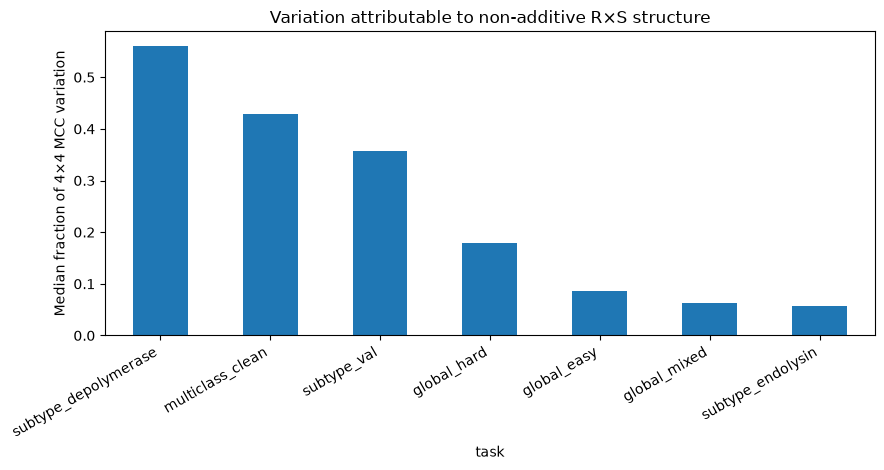

In [26]:
decomposition.groupby("task")[
    "fraction_interaction"
].median().sort_values(ascending=False).plot(
    kind="bar",
    figsize=(9, 4.8),
)
plt.ylabel("Median fraction of 4×4 MCC variation")
plt.title("Variation attributable to non-additive R×S structure")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 16. Where does the additive model systematically miss?

S,90,70,50,30
R,,,,
90,0.011931,0.003645,-0.002649,-0.011998
70,0.002075,0.011743,-0.005991,-0.008555
50,-0.007574,-0.008512,0.005843,0.007581
30,-0.009318,-0.008144,0.004077,0.015986


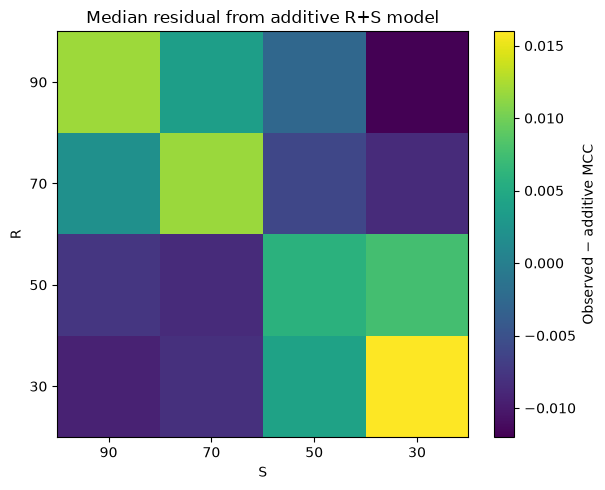

In [27]:
residual_surface = (
    additive_residuals.groupby(["R", "S"])["additive_residual"]
    .median()
    .unstack()
    .reindex(index=R_LEVELS, columns=S_LEVELS)
)

display(residual_surface)

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(residual_surface.to_numpy(), aspect="auto")

ax.set_xticks(range(len(S_LEVELS)), S_LEVELS)
ax.set_yticks(range(len(R_LEVELS)), R_LEVELS)
ax.set_xlabel("S")
ax.set_ylabel("R")
ax.set_title("Median residual from additive R+S model")
plt.colorbar(im, ax=ax, label="Observed − additive MCC")
plt.tight_layout()
plt.show()

A positive residual at `R30_S30`, for example, means that the strict-strict cell performs better than expected from the additive row/column structure of the full surface.

## 17. Threshold-free interaction reconstruction: AP skill and ROC-AUC

In [28]:
def detect_prevalence(df):
    candidates = [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]

    for c in candidates:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = (
            pd.to_numeric(df["tp"], errors="coerce")
            + pd.to_numeric(df["fn"], errors="coerce")
        )
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prevalence, prevalence_source = detect_prevalence(master)
master["prevalence_for_ap"] = prevalence

if "ap" in master.columns:
    denominator = 1 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denominator > 0,
        (master["ap"] - master["prevalence_for_ap"])
        / denominator,
        np.nan,
    )

print("Prevalence source:", prevalence_source)

Prevalence source: prevalence


In [29]:
def build_rectangles_from_master(df, metric, tasks=None):
    rows = []

    work = df.copy()

    if tasks is not None:
        work = work[work["task"].isin(tasks)].copy()

    for keys, grp in work.groupby(
        ["task", "representation", "algorithm"]
    ):
        task, rep, alg = keys

        lookup = {
            (int(r), int(s)): float(v)
            for r, s, v in zip(
                grp["R"],
                grp["S"],
                grp[metric],
            )
            if pd.notna(v)
        }

        for r_loose, r_strict in R_PAIRS:
            for s_loose, s_strict in S_PAIRS:
                corners = [
                    (r_loose, s_loose),
                    (r_strict, s_loose),
                    (r_loose, s_strict),
                    (r_strict, s_strict),
                ]

                if not all(c in lookup for c in corners):
                    continue

                m00 = lookup[(r_loose, s_loose)]
                m10 = lookup[(r_strict, s_loose)]
                m01 = lookup[(r_loose, s_strict)]
                m11 = lookup[(r_strict, s_strict)]

                dR_looseS = m10 - m00
                dR_strictS = m11 - m01
                dS_looseR = m01 - m00
                dS_strictR = m11 - m10

                rows.append(
                    {
                        "task": task,
                        "representation": rep,
                        "algorithm": alg,
                        "metric": metric,
                        "R_loose": r_loose,
                        "R_strict": r_strict,
                        "S_loose": s_loose,
                        "S_strict": s_strict,
                        "interaction": dR_strictS - dR_looseS,
                        "delta_R_at_Sloose": dR_looseS,
                        "delta_R_at_Sstrict": dR_strictS,
                        "delta_S_at_Rloose": dS_looseR,
                        "delta_S_at_Rstrict": dS_strictR,
                    }
                )

    return pd.DataFrame(rows)

thresholdfree_frames = []

if "ap_skill" in master.columns:
    thresholdfree_frames.append(
        build_rectangles_from_master(
            master,
            "ap_skill",
            tasks=BINARY_TASKS,
        )
    )

if "roc_auc" in master.columns:
    thresholdfree_frames.append(
        build_rectangles_from_master(
            master,
            "roc_auc",
            tasks=BINARY_TASKS,
        )
    )

thresholdfree = (
    pd.concat(thresholdfree_frames, ignore_index=True)
    if thresholdfree_frames
    else pd.DataFrame()
)

print(
    "Threshold-free interaction metrics:",
    sorted(thresholdfree["metric"].unique())
    if len(thresholdfree)
    else [],
)

Threshold-free interaction metrics: ['ap_skill', 'roc_auc']


## 18. Extreme interaction across MCC, AP skill, and ROC-AUC

In [30]:
metric_extreme_frames = [
    extreme[
        [
            "task",
            "representation",
            "algorithm",
            "interaction",
        ]
    ].assign(metric="mcc")
]

if len(thresholdfree):
    tf_extreme = thresholdfree[
        thresholdfree["R_loose"].eq(90)
        & thresholdfree["R_strict"].eq(30)
        & thresholdfree["S_loose"].eq(90)
        & thresholdfree["S_strict"].eq(30)
    ][
        [
            "task",
            "representation",
            "algorithm",
            "metric",
            "interaction",
        ]
    ].copy()

    metric_extreme_frames.append(tf_extreme)

metric_extreme = pd.concat(
    metric_extreme_frames,
    ignore_index=True,
)

display(
    metric_extreme.groupby("metric")["interaction"]
    .apply(summarize_interaction)
    .unstack()
)

,n,mean,median,std,q10,q25,q75,q90,min,max,fraction_positive,fraction_negative,median_abs,mean_abs
metric,,,,,,,,,,,,,,
ap_skill,120.0,0.106874,0.039982,0.161241,-0.006264,0.002364,0.145709,0.375665,-0.147522,0.673994,0.783333,0.216667,0.047361,0.115572
mcc,140.0,0.096134,0.051116,0.135443,-0.003893,0.014241,0.114524,0.301702,-0.043694,0.661494,0.885714,0.114286,0.051116,0.100440
roc_auc,120.0,0.031502,0.007911,0.055688,-0.002886,0.000397,0.043718,0.099166,-0.049615,0.300798,0.783333,0.216667,0.008956,0.034328


In [31]:
if {"mcc", "ap_skill", "roc_auc"} <= set(metric_extreme["metric"].unique()):
    wide = metric_extreme.pivot_table(
        index=["task", "representation", "algorithm"],
        columns="metric",
        values="interaction",
        aggfunc="first",
    ).dropna()

    print("Spearman correlations among extreme interaction metrics:")
    display(wide.corr(method="spearman"))

    sign_agreement = pd.DataFrame(
        {
            "MCC_vs_APskill": (
                np.sign(wide["mcc"])
                == np.sign(wide["ap_skill"])
            ).mean(),
            "MCC_vs_ROCAUC": (
                np.sign(wide["mcc"])
                == np.sign(wide["roc_auc"])
            ).mean(),
            "APskill_vs_ROCAUC": (
                np.sign(wide["ap_skill"])
                == np.sign(wide["roc_auc"])
            ).mean(),
        },
        index=["sign_agreement_fraction"],
    )

    display(sign_agreement)

Spearman correlations among extreme interaction metrics:


metric,ap_skill,mcc,roc_auc
metric,,,
ap_skill,1.000000,0.809394,0.839329
mcc,0.809394,1.000000,0.721030
roc_auc,0.839329,0.721030,1.000000


,MCC_vs_APskill,MCC_vs_ROCAUC,APskill_vs_ROCAUC
sign_agreement_fraction,0.783333,0.766667,0.85


## 19. Multiclass interaction check with macro-F1

In [32]:
if "macro_f1" in interactions["metric"].unique():
    multiclass_macro = interactions[
        interactions["metric"].eq("macro_f1")
        & interactions["task"].eq("multiclass_clean")
        & interactions["R_loose"].eq(90)
        & interactions["R_strict"].eq(30)
        & interactions["S_loose"].eq(90)
        & interactions["S_strict"].eq(30)
    ].copy()

    display(
        summarize_interaction(
            multiclass_macro["interaction"]
        ).to_frame("multiclass macro-F1 extreme interaction")
    )
else:
    print("macro_f1 interaction table not available.")

,multiclass macro-F1 extreme interaction
n,20.000000
mean,0.065082
median,0.066684
std,0.046119
q10,0.008357
q25,0.035318
q75,0.093604
q90,0.108015
min,-0.008828
max,0.171775


## 20. Is apparent interaction merely a ceiling artifact?

High-performing surfaces have less headroom for both degradation and positive interaction.

This section examines whether the extreme interaction is strongly associated with the permissive-corner MCC (`R90_S90`).

In [33]:
ceiling_rows = []

for rep, grp in extreme.groupby("representation"):
    x = grp[
        ["M_Rloose_Sloose", "interaction"]
    ].dropna()

    rho_signed = (
        x["M_Rloose_Sloose"].corr(
            x["interaction"],
            method="spearman",
        )
        if len(x) > 3
        else np.nan
    )

    rho_abs = (
        x["M_Rloose_Sloose"].corr(
            x["interaction"].abs(),
            method="spearman",
        )
        if len(x) > 3
        else np.nan
    )

    ceiling_rows.append(
        {
            "representation": rep,
            "n": len(x),
            "rho_baseline_vs_signed_interaction": rho_signed,
            "rho_baseline_vs_abs_interaction": rho_abs,
        }
    )

ceiling_check = pd.DataFrame(ceiling_rows)
display(ceiling_check)

,representation,n,rho_baseline_vs_signed_interaction,rho_baseline_vs_abs_interaction
0,esm2_t30_150m,35,-0.616710,-0.680860
1,esm2_t6_8m,35,-0.133613,-0.145098
2,onehot_1024,35,-0.553719,-0.555680
3,roxy_48,35,0.068627,0.033333


## 21. Interaction regime map: task × representation

In [34]:
task_rep_extreme = (
    extreme.groupby(["task", "representation"])
    .agg(
        median_interaction=("interaction", "median"),
        median_abs_interaction=(
            "interaction",
            lambda x: x.abs().median(),
        ),
        fraction_positive=(
            "interaction",
            lambda x: (x > INTERACTION_TOL).mean(),
        ),
        fraction_near_additive=(
            "interaction",
            lambda x: (x.abs() <= INTERACTION_TOL).mean(),
        ),
        fraction_negative=(
            "interaction",
            lambda x: (x < -INTERACTION_TOL).mean(),
        ),
    )
    .reset_index()
)

display(task_rep_extreme)

,task,representation,median_interaction,median_abs_interaction,fraction_positive,fraction_near_additive,fraction_negative
0,global_easy,esm2_t30_150m,0.024921,0.024921,1.0,0.0,0.0
1,global_easy,esm2_t6_8m,0.045886,0.045886,1.0,0.0,0.0
2,global_easy,onehot_1024,0.158906,0.158906,1.0,0.0,0.0
3,global_easy,roxy_48,0.048290,0.048290,0.6,0.2,0.2
4,global_hard,esm2_t30_150m,0.002834,0.004988,0.4,0.6,0.0
5,global_hard,esm2_t6_8m,0.017787,0.017787,0.6,0.4,0.0
6,global_hard,onehot_1024,0.041352,0.041352,0.8,0.0,0.2
7,global_hard,roxy_48,0.057686,0.057686,0.8,0.0,0.2
8,global_mixed,esm2_t30_150m,-0.004001,0.009512,0.0,0.6,0.4
9,global_mixed,esm2_t6_8m,0.008395,0.011608,0.4,0.4,0.2


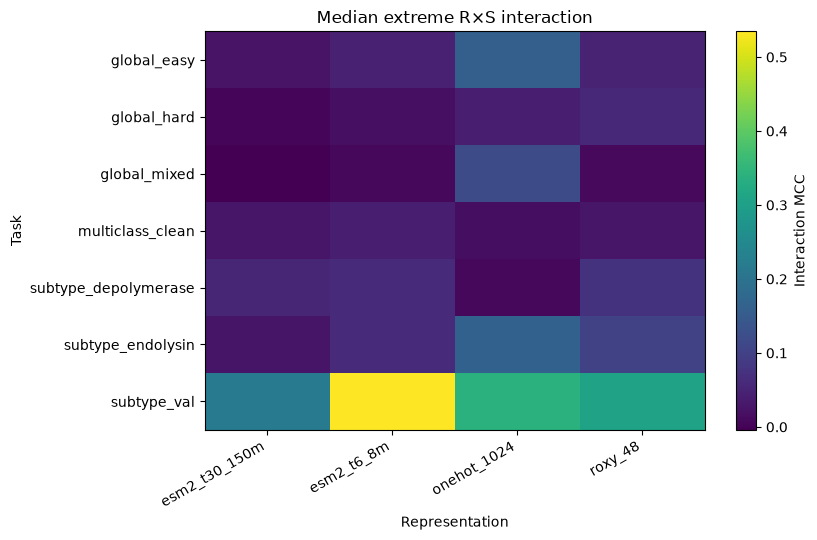

In [35]:
pivot = (
    task_rep_extreme.pivot(
        index="task",
        columns="representation",
        values="median_interaction",
    )
)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(pivot.to_numpy(), aspect="auto")

ax.set_xticks(
    range(len(pivot.columns)),
    pivot.columns,
    rotation=30,
    ha="right",
)
ax.set_yticks(
    range(len(pivot.index)),
    pivot.index,
)

ax.set_xlabel("Representation")
ax.set_ylabel("Task")
ax.set_title("Median extreme R×S interaction")
plt.colorbar(im, ax=ax, label="Interaction MCC")
plt.tight_layout()
plt.show()

# 22. RQ4 synthesis

After execution, RQ4 should answer:

1. Is the full R×S surface approximately additive?
2. What is the direction and magnitude of the extreme interaction?
3. Does the strict-strict corner generally perform better or worse than additive expectation?
4. How much of the additive joint penalty is offset by interaction?
5. Which biological tasks show the strongest attenuation or amplification?
6. Which representations show the strongest/weakest non-additivity?
7. Which learners are most interaction-sensitive?
8. Where in the 3×3 local interval map is the interaction concentrated?
9. Is there a universal local interaction hotspot?
10. How much of the total 4×4 surface variation is attributable to non-additive structure?
11. Does the additive residual systematically concentrate at strict R/S?
12. Is the interaction preserved in threshold-free metrics?
13. Is the interaction compatible with a simple ceiling effect?
14. Does the evidence support the hypothesis that aggressive redundancy control reduces the additional cost of remote homology separation?

In [36]:
rq4_rows = []

# Global all-rectangle summary.
g = summarize_interaction(
    mcc_interactions["interaction"]
)

rq4_rows.append(
    {
        "evidence": "all_MCC_rectangles",
        "group": "all",
        "n": g["n"],
        "median_interaction": g["median"],
        "mean_interaction": g["mean"],
        "median_abs_interaction": g["median_abs"],
        "fraction_positive": g["fraction_positive"],
        "fraction_negative": g["fraction_negative"],
    }
)

# Extreme summary.
g = summarize_interaction(
    extreme["interaction"]
)

rq4_rows.append(
    {
        "evidence": "extreme_R90_R30_S90_S30",
        "group": "all",
        "n": g["n"],
        "median_interaction": g["median"],
        "mean_interaction": g["mean"],
        "median_abs_interaction": g["median_abs"],
        "fraction_positive": g["fraction_positive"],
        "fraction_negative": g["fraction_negative"],
    }
)

# By task.
for task, row in task_extreme.iterrows():
    rq4_rows.append(
        {
            "evidence": "extreme_by_task",
            "group": task,
            "n": row["n"],
            "median_interaction": row["median"],
            "mean_interaction": row["mean"],
            "median_abs_interaction": row["median_abs"],
            "fraction_positive": row["fraction_positive"],
            "fraction_negative": row["fraction_negative"],
        }
    )

# By representation.
for rep, row in rep_extreme.iterrows():
    rq4_rows.append(
        {
            "evidence": "extreme_by_representation",
            "group": rep,
            "n": row["n"],
            "median_interaction": row["median"],
            "mean_interaction": row["mean"],
            "median_abs_interaction": row["median_abs"],
            "fraction_positive": row["fraction_positive"],
            "fraction_negative": row["fraction_negative"],
        }
    )

# Decomposition.
rq4_rows.append(
    {
        "evidence": "factorial_decomposition",
        "group": "all",
        "median_fraction_R": decomposition["fraction_R"].median(),
        "median_fraction_S": decomposition["fraction_S"].median(),
        "median_fraction_interaction": decomposition[
            "fraction_interaction"
        ].median(),
        "median_interaction_rms": decomposition[
            "interaction_rms"
        ].median(),
    }
)

rq4_summary = pd.DataFrame(rq4_rows)
display(rq4_summary)

SUMMARY_PATH = CACHE_DIR / "rq4_evidence_summary.tsv"
EXTREME_PATH = CACHE_DIR / "rq4_extreme_mcc_interactions.tsv"
LOCAL_PATH = CACHE_DIR / "rq4_local_adjacent_interactions.tsv"
DECOMP_PATH = CACHE_DIR / "rq4_factorial_decomposition.tsv"
RESIDUAL_PATH = CACHE_DIR / "rq4_additive_surface_residuals.tsv"
THRESHOLDFREE_PATH = CACHE_DIR / "rq4_thresholdfree_interactions.tsv"
TASKREP_PATH = CACHE_DIR / "rq4_task_representation_interaction_map.tsv"

rq4_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
extreme.to_csv(EXTREME_PATH, sep="\t", index=False)
local.to_csv(LOCAL_PATH, sep="\t", index=False)
decomposition.to_csv(DECOMP_PATH, sep="\t", index=False)
additive_residuals.to_csv(RESIDUAL_PATH, sep="\t", index=False)
thresholdfree.to_csv(THRESHOLDFREE_PATH, sep="\t", index=False)
task_rep_extreme.to_csv(TASKREP_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    EXTREME_PATH,
    LOCAL_PATH,
    DECOMP_PATH,
    RESIDUAL_PATH,
    THRESHOLDFREE_PATH,
    TASKREP_PATH,
]:
    print(" ", p)

,evidence,group,n,median_interaction,mean_interaction,median_abs_interaction,fraction_positive,fraction_negative,median_fraction_R,median_fraction_S,median_fraction_interaction,median_interaction_rms
0,all_MCC_rectangles,all,5040.0,0.014679,0.031515,0.028728,0.659524,0.325794,NaN,NaN,NaN,NaN
1,extreme_R90_R30_S90_S30,all,140.0,0.051116,0.096134,0.051116,0.885714,0.114286,NaN,NaN,NaN,NaN
2,extreme_by_task,subtype_val,20.0,0.339206,0.354234,0.339206,1.000000,0.000000,NaN,NaN,NaN,NaN
3,extreme_by_task,subtype_endolysin,20.0,0.080343,0.094910,0.080343,0.950000,0.050000,NaN,NaN,NaN,NaN
4,extreme_by_task,subtype_depolymerase,20.0,0.061084,0.058496,0.061084,0.900000,0.100000,NaN,NaN,NaN,NaN
5,extreme_by_task,global_easy,20.0,0.047088,0.068535,0.047088,0.950000,0.050000,NaN,NaN,NaN,NaN
6,extreme_by_task,multiclass_clean,20.0,0.028747,0.031212,0.029222,0.900000,0.100000,NaN,NaN,NaN,NaN
7,extreme_by_task,global_hard,20.0,0.021067,0.026313,0.022814,0.800000,0.200000,NaN,NaN,NaN,NaN
8,extreme_by_task,global_mixed,20.0,0.010090,0.039235,0.017270,0.700000,0.300000,NaN,NaN,NaN,NaN
9,extreme_by_representation,onehot_1024,35.0,0.121947,0.140924,0.121947,0.885714,0.114286,NaN,NaN,NaN,NaN


Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq4_evidence_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq4_extreme_mcc_interactions.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq4_local_adjacent_interactions.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq4_factorial_decomposition.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq4_additive_surface_residuals.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq4_thresholdfree_interactions.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_p

## What this notebook should not conclude

Do not call every positive interaction “biological synergy” or “antagonism”. These are **predictive factorial interactions**.

Do not treat native-cell interaction estimates as protein-level paired effects.

Do not infer that R and S are redundant merely because one attenuates the effect of the other. They modify different components of the evaluation protocol.

Do not use the descriptive variance decomposition as an inferential ANOVA.

The strongest defensible claim, if supported, is:

> **the predictive cost of redundancy reduction and train–test homology separation is non-additive, with one factor changing the marginal effect of the other across the generalization landscape.**